# ¿Se ve la sequía desde el espacio antes de la cosecha?

**Lo que ven los satélites antes que Wall Street** · NASA Space Apps Challenge Mendoza · 13-11-2026 · Lucas Trubiano, Trubi Data

En la campaña 2022/23 una sequía histórica se llevó cerca de un tercio de la soja argentina. Pregunta de esta demo: **con el verdor de los cultivos visto desde el espacio en enero-marzo, ¿se puede anticipar el rinde de cada departamento antes de que se publique la cosecha?**

El hilo: **hay estos datos → cómo los procesamos → qué predecimos con IA.**

> Es una demo educativa. No es un modelo para usar en producción ni para invertir.

## 0. Configuración

Corre igual en tu máquina y en Google Colab. En Colab, la primera celda clona el repo e instala todo.

`EXTRAER = False` usa las features ya calculadas (`data/processed/features.csv`), así que **no hace falta cuenta de Earth Engine**. Con `True` las recalcula en Earth Engine con tu proyecto.

In [1]:
import sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not Path("satelites-datos-ia").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/lucastrubiano/satelites-datos-ia"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "satelites-datos-ia"], check=True)
    sys.path.insert(0, "satelites-datos-ia/src")

RAIZ = Path("satelites-datos-ia") if EN_COLAB else Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS, SALIDAS = RAIZ / "data", RAIZ / "salidas"
SALIDAS.mkdir(exist_ok=True)

EXTRAER = False                    # True: recalcular features en Earth Engine
PROYECTO_EE = "satelites-datos-ia"  # tu proyecto de Earth Engine (tier Community, gratis)
CAMPANIAS = range(2000, 2025)      # 2000 = campaña 2000/2001
N_DEPARTAMENTOS = 100

## 1. Los datos

| Pieza | Fuente | Licencia |
|---|---|---|
| Rinde de soja por departamento y campaña | MAGyP, [datos.gob.ar](https://datos.gob.ar/dataset/soja-siembra-cosecha-produccion-rendimiento) | CC-BY 4.0 |
| Polígonos de departamentos (código INDEC) | IGN, vía [Georef](https://datos.gob.ar/dataset/servicio-de-normalizacion-de-direcciones-y-unidades-territoriales-de-argentina) | CC-BY 4.0 |
| Verdor (NDVI) 250 m, cada 16 días, desde 2000 | NASA MODIS `MOD13Q1` v061, en Earth Engine | Datos abiertos de NASA |
| Lluvia diaria ~5 km | CHIRPS, en Earth Engine | Abierta |
| Dónde hay cultivos (10 m) | ESA WorldCover 2021, clase 40 | CC-BY 4.0 |

Todo gratis y sin tarjeta.

In [2]:
import pandas as pd
from satdemo import rinde, features, modelo

csv_soja = rinde.bajar(rinde.URL_SOJA, DATOS / "raw" / "soja-serie-1941-2024.csv")
geo_deptos = rinde.bajar(rinde.URL_DEPARTAMENTOS, DATOS / "raw" / "departamentos.geojson")

soja = rinde.principales(rinde.cargar(csv_soja), N_DEPARTAMENTOS)
print(f"{soja.departamento_id.nunique()} departamentos × {soja.anio.nunique()} campañas = {len(soja)} filas")
soja.groupby("provincia").departamento_id.nunique().sort_values(ascending=False)

100 departamentos × 25 campañas = 2500 filas


provincia
Buenos Aires           45
Córdoba                17
Santa Fe               15
Entre Ríos             10
Chaco                   4
Santiago del Estero     4
Salta                   3
La Pampa                2
Name: departamento_id, dtype: int64

Los **100 departamentos con más soja sembrada** entre 2000 y 2024, con dato en todas las campañas. Una regla objetiva en vez de dibujar a mano la zona núcleo.

Así se ve la sequía en el dato oficial:

Matplotlib is building the font cache; this may take a moment.


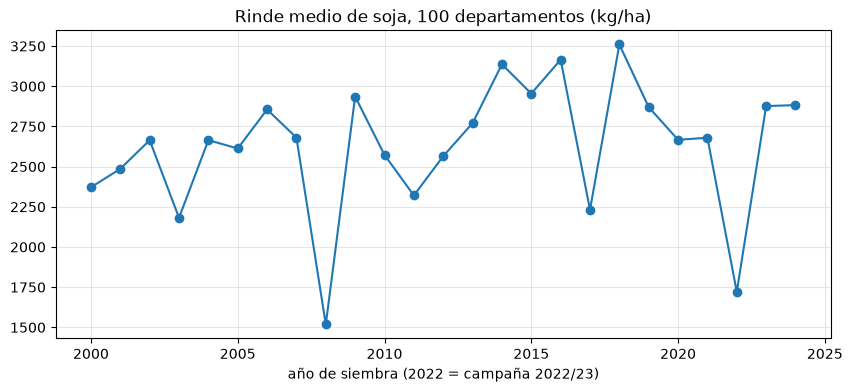

In [3]:
ax = soja.groupby("anio").rendimiento_kgxha.mean().plot(marker="o", figsize=(10, 4), title="Rinde medio de soja, 100 departamentos (kg/ha)")
ax.set_xlabel("año de siembra (2022 = campaña 2022/23)"); ax.grid(alpha=.3);

## 2. Cómo los procesamos: el satélite no se baja, se consulta

Una escena MODIS pesa cientos de MB y necesitamos ~150 escenas por año durante 25 años. **No bajamos nada**: le mandamos la cuenta a Earth Engine, que la hace en sus servidores al lado del dato, y nos devuelve una tabla de 2.500 filas.

Por cada departamento y campaña:
1. **Filtrar** las imágenes de enero a marzo (llenado de granos).
2. **Limpiar**: descartar píxeles con nubes o mala calidad (`SummaryQA`) y quedarse solo con píxeles de cultivo (WorldCover).
3. **Reducir**: NDVI máximo y medio, promediado sobre el polígono del departamento.
4. **Lluvia** acumulada de noviembre a marzo (CHIRPS).

El código está en `src/satdemo/features.py`.

In [4]:
if EXTRAER:
    import ee
    if EN_COLAB:
        ee.Authenticate()
    ee.Initialize(project=PROYECTO_EE)
    deptos = features.departamentos_ee(geo_deptos, sorted(soja.departamento_id.unique()))
    feats = features.extraer(deptos, CAMPANIAS)
    feats.to_csv(DATOS / "processed" / "features.csv", index=False)
else:
    feats = pd.read_csv(DATOS / "processed" / "features.csv", dtype={"departamento_id": str})

panel = soja.merge(feats, on=["departamento_id", "anio"])
panel[["anio", "departamento", "provincia", "rendimiento_kgxha", "ndvi_max", "ndvi_media", "lluvia_mm"]].sample(5, random_state=1)

,anio,departamento,provincia,rendimiento_kgxha,ndvi_max,ndvi_media,lluvia_mm
1406,2014,Azul,Buenos Aires,2032,0.766506,0.643665,398.764018
297,2002,General Taboada,Santiago del Estero,2525,0.814947,0.708898,667.055953
1276,2012,Chapaleufú,La Pampa,2961,0.796046,0.680644,409.020587
2368,2023,Gualeguaychú,Entre Ríos,2589,0.807144,0.673021,976.232593
438,2004,Saladillo,Buenos Aires,3235,0.796446,0.722657,717.935976


## 3. ¿Hay señal? Anomalías, no valores

Un departamento siempre más verde que otro no dice nada. Lo que importa es **cuánto se aparta cada departamento de su propio promedio**: eso es una anomalía, y es como sacamos la estacionalidad y las diferencias de suelo.

Correlación anomalía de NDVI máximo vs. anomalía de rinde: 0.70


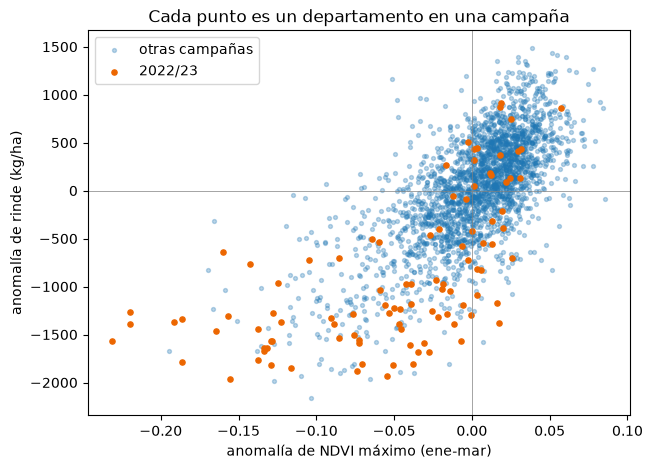

In [5]:
print(f"Correlación anomalía de NDVI máximo vs. anomalía de rinde: {modelo.correlacion(panel):.2f}")

import matplotlib.pyplot as plt
g = panel.groupby("departamento_id")
an = panel.assign(ndvi_anom=panel.ndvi_max - g.ndvi_max.transform("mean"),
                  rinde_anom=panel.rendimiento_kgxha - g.rendimiento_kgxha.transform("mean"))
fig, ax = plt.subplots(figsize=(7, 5))
otros, sequia = an[an.anio != 2022], an[an.anio == 2022]
ax.scatter(otros.ndvi_anom, otros.rinde_anom, s=8, alpha=.3, label="otras campañas")
ax.scatter(sequia.ndvi_anom, sequia.rinde_anom, s=14, color="#ec6600", label="2022/23")
ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
ax.set_xlabel("anomalía de NDVI máximo (ene-mar)"); ax.set_ylabel("anomalía de rinde (kg/ha)")
ax.set_title("Cada punto es un departamento en una campaña"); ax.legend()
fig.savefig(SALIDAS / "dispersion_ndvi_rinde.png", dpi=150, bbox_inches="tight")

## 4. El mapa de la sequía

NDVI máximo de enero-marzo 2023, como anomalía contra el promedio de cada departamento, al lado de la anomalía de rinde que publicó MAGyP meses después.

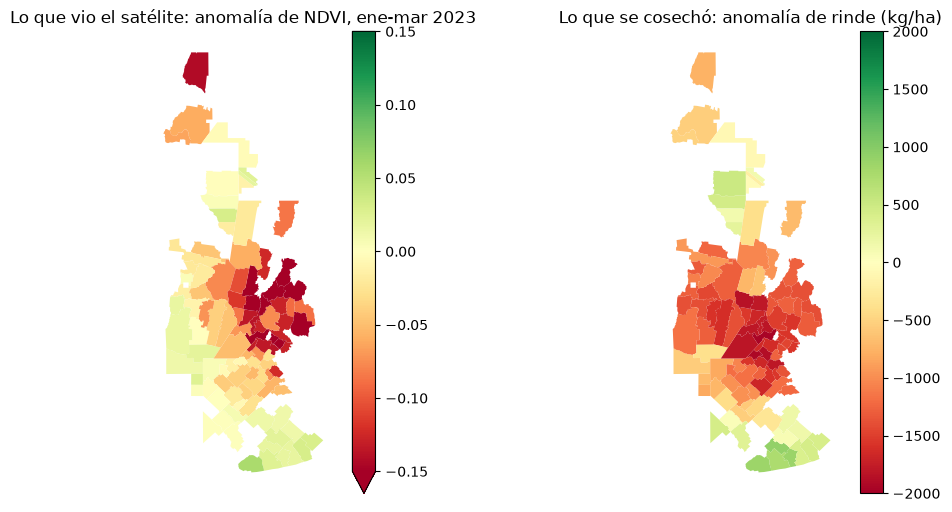

In [6]:
import geopandas as gpd
mapa = gpd.read_file(geo_deptos).rename(columns={"id": "departamento_id"})
m22 = mapa.merge(an[an.anio == 2022], on="departamento_id")
fig, ejes = plt.subplots(1, 2, figsize=(12, 6))
m22.plot("ndvi_anom", cmap="RdYlGn", vmin=-.15, vmax=.15, legend=True, ax=ejes[0])
m22.plot("rinde_anom", cmap="RdYlGn", vmin=-2000, vmax=2000, legend=True, ax=ejes[1])
ejes[0].set_title("Lo que vio el satélite: anomalía de NDVI, ene-mar 2023")
ejes[1].set_title("Lo que se cosechó: anomalía de rinde (kg/ha)")
for e in ejes: e.set_axis_off()
fig.savefig(SALIDAS / "mapa_sequia_2022.png", dpi=150, bbox_inches="tight")

## 5. Qué predecimos: baseline primero, modelo después

1. **Baseline**: el rinde de siempre (promedio histórico del departamento). Si un modelo no le gana a esto, no sirve.
2. **Regresión lineal** con las anomalías de NDVI y lluvia.
3. **Gradient boosting** (`scikit-learn`).

**Validación honesta:** para predecir una campaña se entrena **solo con las campañas anteriores**, y las anomalías se calculan con esos promedios. Mezclar años al azar filtraría el futuro y daría un error falsamente bajo.

Métrica: error porcentual absoluto medio (MAPE) del rinde por departamento.

In [7]:
pred = modelo.validar(panel, desde=2008)
err = modelo.errores(pred)
print(modelo.resumen(err))
err

baseline    26.9
lineal      16.3
boosting    16.9
Name: MAPE %, dtype: float64


,baseline,lineal,boosting
anio,,,
2008,92.7,43.9,54.1
2009,20.2,10.2,11.0
2010,13.1,11.3,12.0
2011,30.3,15.3,13.5
2012,19.5,15.5,15.1
2013,16.3,11.4,11.8
2014,19.7,12.6,13.3
2015,20.5,13.5,14.5
2016,18.8,12.9,12.6


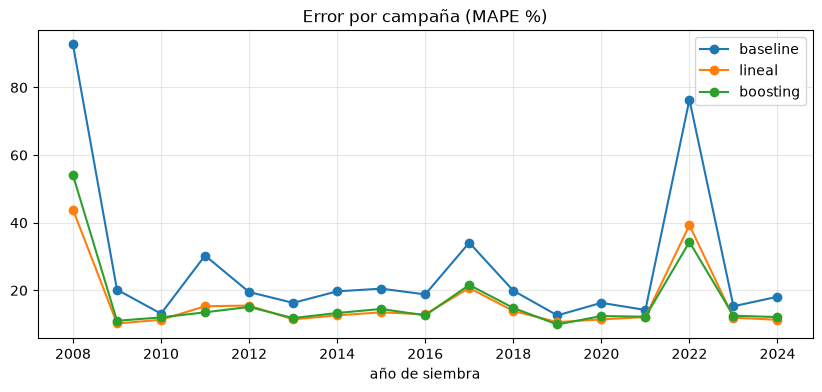

In [8]:
ax = err.plot(marker="o", figsize=(10, 4), title="Error por campaña (MAPE %)")
ax.set_xlabel("año de siembra"); ax.grid(alpha=.3)
ax.figure.savefig(SALIDAS / "error_por_campania.png", dpi=150, bbox_inches="tight")

## 6. El remate: 2022/23

Rinde real medio:      1,720 kg/ha
Predicción baseline   2,644 kg/ha
Predicción lineal     1,890 kg/ha
Predicción boosting   2,000 kg/ha


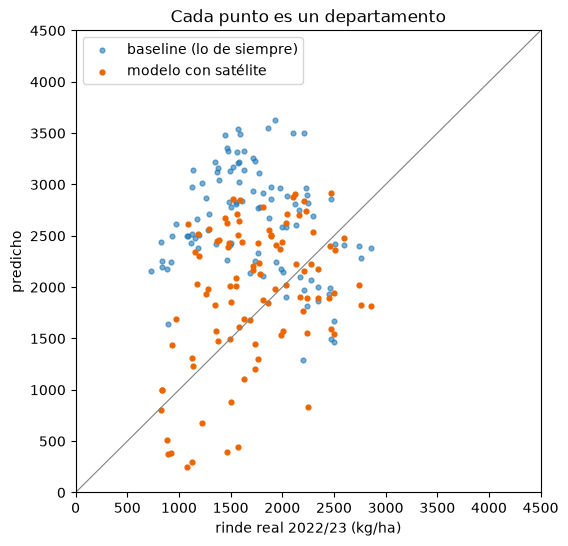

In [9]:
p22 = pred[pred.anio == 2022]
print(f"Rinde real medio:      {p22.rendimiento_kgxha.mean():,.0f} kg/ha")
for m in ("baseline", "lineal", "boosting"):
    print(f"Predicción {m:<9}  {p22[f'pred_{m}'].mean():,.0f} kg/ha")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(p22.rendimiento_kgxha, p22.pred_baseline, s=12, alpha=.6, label="baseline (lo de siempre)")
ax.scatter(p22.rendimiento_kgxha, p22.pred_lineal, s=12, color="#ec6600", label="modelo con satélite")
lim = [0, 4500]; ax.plot(lim, lim, color="gray", lw=.8)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("rinde real 2022/23 (kg/ha)"); ax.set_ylabel("predicho"); ax.legend()
ax.set_title("Cada punto es un departamento")
fig.savefig(SALIDAS / "predicho_vs_real_2022.png", dpi=150, bbox_inches="tight")

## Qué nos llevamos

- **El dato no se baja, se consulta**: Earth Engine (o STAC + COG) computa al lado del dato.
- **Limpiar es la mitad del trabajo**: nubes, calidad, máscara de cultivo.
- **Anomalías, no valores**: cada lugar contra sí mismo.
- **Baseline primero**: el modelo baja el error de ~27 % a ~16 % y, en la sequía, se acerca mucho más al real.
- **Un modelo simple alcanza**: con 2.500 filas, la regresión lineal empata o le gana al boosting.
- **Validá hacia adelante en el tiempo**, nunca al azar.

**Límites:** 25 campañas; NDVI de 250 m mezcla soja con otros cultivos; el dato satelital llega en marzo, pero la estimación oficial de MAGyP también se va publicando durante la campaña. Para la hackathon: cambiá el cultivo (maíz, trigo), la variable o el polígono.

Repo: https://github.com/lucastrubiano/satelites-datos-ia